# Solar Filament Segmentation 2026: end-to-end pipeline

Reproduces the full submission from the committed weights **without retraining**:

1. Environment and configuration
2. Data loading and the fixed, timestamp-grouped train/validation split
3. *(optional)* Training (`RUN_TRAINING = True`; ~3.5 h on a GTX 1650 with the GPU to itself)
4. Model loading (class-agnostic Mask R-CNN, ResNet50-FPN)
5. Validation: Panoptic Quality, Dice (incl. `torchmetrics.DiceScore`), IoU/Dice distributions, one-to-many / many-to-one counts
6. Qualitative results: masks overlaid on H-alpha images
7. Test-set inference, submission CSV (RLE) and format checks
8. Computational cost

**Method in one paragraph.** Each 2048x2048 grayscale GONG H-alpha image is fed at native resolution to a
torchvision Mask R-CNN (ResNet50-FPN, COCO-pretrained) fine-tuned with a single *filament* class. Only the
segmentation polygons are used as targets (no spines, boxes or chirality labels, per the rules). Training
uses random 1024x1024 full-resolution crops (80% centred near a filament) with flips, 90-degree rotations and
brightness/contrast/gamma jitter. At inference, detections are converted to non-overlapping instances by
greedy score-ordered painting; the score threshold, mask threshold and minimum area are tuned on the
validation split only. At test time, predictions from the original, horizontally flipped and
vertically flipped image are fused per instance (mean mask probability; score averaged over the
three views), see `src/tta.py`.

Run from the repository root or from `notebooks/`; the first cell sets the working directory.

In [1]:
import os, sys, json, time
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))

# ---- user settings ---------------------------------------------------------
CONFIG       = "configs/baseline_tta.yaml"         # final: epoch-24 model + flip TTA
WEIGHTS      = "weights/maskrcnn_r50_filament.pt"        # committed final weights
PP_FILE      = "weights/maskrcnn_r50_filament_tta.pp.json"  # post-processing tuned on validation (with TTA)
SUBMISSION   = "submissions/submission.csv"
RUN_TRAINING = False   # True = retrain from COCO weights (hours); False = use committed weights
RUN_VAL      = True    # validation metrics + figures (~8 min on GTX 1650 with TTA)
# ---------------------------------------------------------------------------
print("project root:", ROOT)

project root: C:\Users\sagar\Downloads\Optoelectronics\python\kaggle comp


In [2]:
import numpy as np, pandas as pd, torch, torchvision, matplotlib.pyplot as plt
from pycocotools import mask as mask_utils
from src.utils import load_config, resolve, seed_everything, get_device
from src.data import load_samples, get_split, read_gray, observatory
from src.models import build_model, load_weights
from src.predict import PP_KEYS, ValSet, run_inference, write_submission, validate_submission
from src.postprocess import postprocess, instances_to_rles
from src.metrics import aggregate, fmt, torchmetrics_dice
from src.visualize import show_pair

cfg = load_config(CONFIG)
seed_everything(cfg["seed"])
device = get_device()
print(f"torch {torch.__version__} | torchvision {torchvision.__version__} | device {device}"
      + (f" ({torch.cuda.get_device_name(0)})" if device.type == "cuda" else ""))
print("seed", cfg["seed"])

torch 2.14.1+cu126 | torchvision 0.29.1+cu126 | device cuda (NVIDIA GeForce GTX 1650)
seed 42


## 2. Data and validation split

One *sample* = one annotator's labels of one image; images labelled by several annotators appear several
times. The split is grouped by image timestamp (an image is never in both train and validation), stratified
by observatory, and saved in `splits/` so every experiment uses the same one.

1154 samples, 707 unique images, 8199 filaments


set,train images,val images
obs,,
Bh,100,18
Ch,106,19
Lh,108,19
Mh,106,19
Th,94,16
Uh,87,15


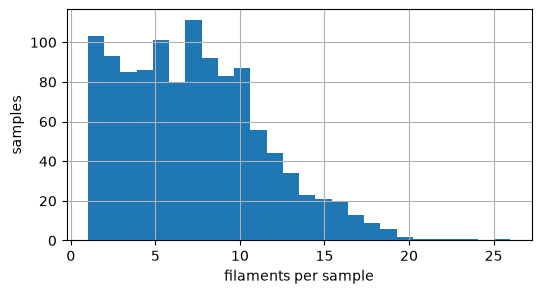

In [3]:
data_root = resolve(cfg["data"]["root"])
samples = load_samples(data_root / cfg["data"]["train_json"])
split = get_split(samples, resolve(cfg["data"]["split_file"]), cfg["data"]["val_frac"], cfg["seed"])
val_ts = set(split["val"])
df = pd.DataFrame([{"timestamp": s["timestamp"], "obs": observatory(s["timestamp"]), "n_inst": len(s["polygons"]),
                    "set": "val" if s["timestamp"] in val_ts else "train"} for s in samples])
print(f"{len(samples)} samples, {df.timestamp.nunique()} unique images, {df.n_inst.sum()} filaments")
display(df.groupby(["set", "obs"]).timestamp.nunique().unstack(0).add_suffix(" images"))
fig, ax = plt.subplots(figsize=(6, 3)); df.n_inst.hist(bins=26, ax=ax)
ax.set_xlabel("filaments per sample"); ax.set_ylabel("samples"); plt.show()

## 3. Training (optional)

Skipped by default; the committed weights are used. `RUN_TRAINING = True` runs `python -m src.train`, which
writes `runs/<name>_<time>/` (log, `best.pt`, tuned `best.pp.json`) and appends to `results/results.csv`.

In [4]:
if RUN_TRAINING:
    import subprocess, glob
    subprocess.run([sys.executable, "-m", "src.train", "--config", CONFIG], check=True)
    run = sorted(glob.glob("runs/*/best.pt"), key=os.path.getmtime)[-1]
    WEIGHTS, PP_FILE = run, run.replace(".pt", ".pp.json")
    print("using freshly trained", WEIGHTS)

## 4. Load model

In [5]:
t0 = time.time()
model = build_model(cfg["model"], pretrained=False)
load_weights(model, WEIGHTS)
model.to(device).eval()
pp = {**cfg["postprocess"], **json.loads(Path(PP_FILE).read_text())}
n_params = sum(p.numel() for p in model.parameters())
print(f"loaded {WEIGHTS} ({Path(WEIGHTS).stat().st_size / 2**20:.0f} MB, {n_params / 1e6:.1f} M params) in {time.time() - t0:.1f}s")
print("post-processing:", pp)

C:\Users\sagar\Downloads\Optoelectronics\python\kaggle comp\.venv\Lib\site-packages\torchvision\models\detection\backbone_utils.py:162: UserWarning: Changing trainable_backbone_layers has no effect if neither pretrained nor pretrained_backbone have been set to True, falling back to trainable_backbone_layers=5 so that all layers are trainable
  warnings.warn(


loaded weights/maskrcnn_r50_filament.pt (84 MB, 44.0 M params) in 0.8s
post-processing: {'score_thr': 0.8, 'mask_thr': 0.5, 'min_area': 0, 'overlap_keep': 0.5}


## 5. Validation metrics

PQ = sum IoU(TP) / (|TP| + 0.5|FP| + 0.5|FN|), a match when IoU > 0.5. `pq` pools all validation samples;
`pq_img` is the mean over samples. *One-to-many*: a GT covered by >=2 predictions each >50% inside it
(fragmentation). *Many-to-one*: a prediction covering >=2 GTs each >50% inside it (over-merging).

In [6]:
if RUN_VAL:
    vs = ValSet(cfg)
    t0 = time.time()
    val_dets = run_inference(model, vs.paths, cfg["model"], device, amp=cfg["train"]["amp"], desc="val")
    t_val = time.time() - t0
    preds = vs.predictions(val_dets, pp)
    per = vs.per_image(val_dets, pp)
    m = aggregate(per)
    print(fmt(m))
    print(f"inference: {len(vs.paths)} images in {t_val:.0f}s ({t_val / len(vs.paths):.2f} s/img)")
    display(pd.Series(m, name="validation").to_frame().T.round(4))

val:   0%|          | 0/106 [00:00<?, ?it/s]

val:   1%|          | 1/106 [00:03<05:48,  3.32s/it]

val:   2%|▏         | 2/106 [00:06<05:27,  3.15s/it]

val:   3%|▎         | 3/106 [00:09<05:22,  3.13s/it]

val:   4%|▍         | 4/106 [00:12<05:12,  3.06s/it]

val:   5%|▍         | 5/106 [00:15<05:07,  3.04s/it]

... (99 outputs left out)

val:  99%|█████████▉| 105/106 [05:25<00:03,  3.00s/it]

val: 100%|██████████| 106/106 [05:28<00:00,  2.99s/it]

PQ 0.4193 (img 0.4204) SQ 0.671 RQ 0.625 | TP 706 FP 415 FN 432 | Dice sem 0.662 perGT 0.595 | 1:N 43 N:1 27
inference: 106 images in 328s (3.10 s/img)


,pq,pq_img,sq,rq,tp,fp,fn,dice_sem,dice_per_gt,iou_matched_mean,one_to_many,many_to_one,n_pred,n_gt
validation,0.4193,0.4204,0.6708,0.6251,706.0,415.0,432.0,0.662,0.5949,0.6708,43.0,27.0,1121.0,1138.0


In [7]:
if RUN_VAL:
    tm = [torchmetrics_dice(preds[s["timestamp"]], vs.gt[s["sample_id"]]) for s in vs.samples]
    print(f"mean Dice (torchmetrics.segmentation.DiceScore, per sample): {np.mean(tm):.4f}")

mean Dice (torchmetrics.segmentation.DiceScore, per sample): 0.6620


### Organisers' self-evaluation code

`src/official_eval.py` contains the scoring functions from the competition's self-evaluation
notebook, unchanged. Their PQ must equal ours; their IoU/Dice distributions are over all
*overlapping* (GT, prediction) pairs, and their 1:n / n:1 counts use *any* overlap (IoU > 0).

In [8]:
if RUN_VAL:
    from src.official_eval import official_report, rles_df
    off = official_report(rles_df(vs.gt), rles_df(preds))
    assert abs(off["pq"] - m["pq"]) < 1e-6, (off["pq"], m["pq"])
    print(f"official PQ {off['pq']:.4f} (ours {m['pq']:.4f})")
    print(f"pairwise IoU mean {off['pairwise_iou_mean']:.3f}, pairwise Dice mean {off['pairwise_dice_mean']:.3f} "
          f"over {off['n_overlapping_pairs']} overlapping pairs")
    print(f"GT: misses {off['gt_misses_1:0']}, hits {off['gt_hits_1:n']}, one-to-many (1:n, n>=2) {off['gt_one_to_many_1:n>=2']}  "
          f"| degrees {off['gt_degree']}")
    print(f"pred: misses {off['pred_misses_0:1']}, hits {off['pred_hits_n:1']}, many-to-one (n:1, n>=2) {off['pred_many_to_one_n>=2:1']}  "
          f"| degrees {off['pred_degree']}")

official PQ 0.4193 (ours 0.4193)
pairwise IoU mean 0.567, pairwise Dice mean 0.702 over 988 overlapping pairs
GT: misses 212, hits 926, one-to-many (1:n, n>=2) 56  | degrees {0: 212, 1: 870, 2: 50, 3: 6}
pred: misses 174, hits 947, many-to-one (n:1, n>=2) 40  | degrees {0: 174, 1: 907, 2: 39, 3: 1}


### IoU / Dice distributions

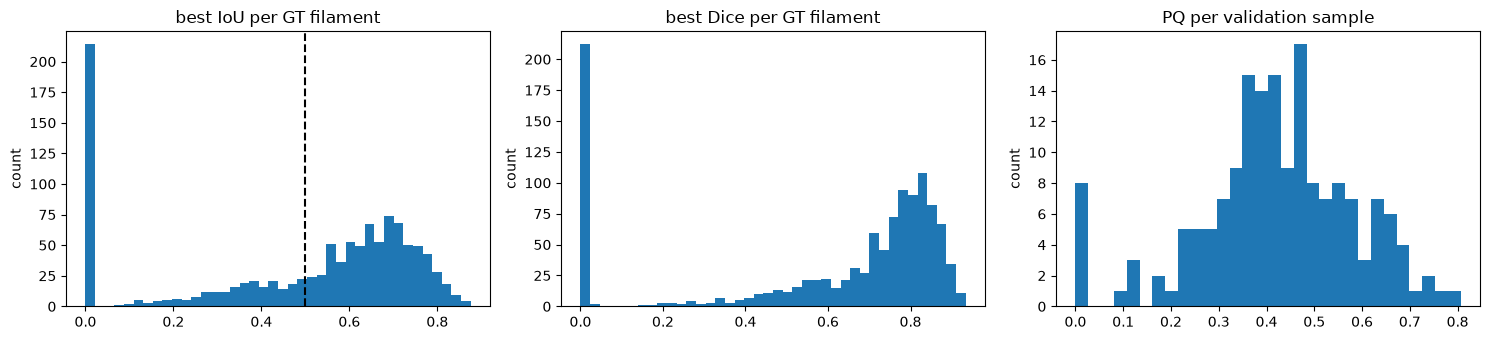

matched IoU: mean 0.671, median 0.677; GT filaments with best IoU > 0.5: 62.0%


In [9]:
if RUN_VAL:
    matched = np.array([x for r in per for x in r["matched_iou"]])
    best = np.array([x for r in per for x in r["best_iou_per_gt"]])
    pq_s = np.array([r["sum_iou"] / max(r["tp"] + .5 * r["fp"] + .5 * r["fn"], 1e-9) for r in per])
    fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
    ax[0].hist(best, bins=40); ax[0].axvline(.5, c="k", ls="--"); ax[0].set_title("best IoU per GT filament")
    ax[1].hist(2 * best / (1 + best), bins=40); ax[1].set_title("best Dice per GT filament")
    ax[2].hist(pq_s, bins=30); ax[2].set_title("PQ per validation sample")
    for a in ax: a.set_ylabel("count")
    plt.tight_layout(); plt.show()
    print(f"matched IoU: mean {matched.mean():.3f}, median {np.median(matched):.3f}; "
          f"GT filaments with best IoU > 0.5: {(best > .5).mean():.1%}")

## 6. Qualitative results (validation)

Ground truth (left) and prediction (right) for the best, median and worst validation samples by PQ,
then a zoomed crop.

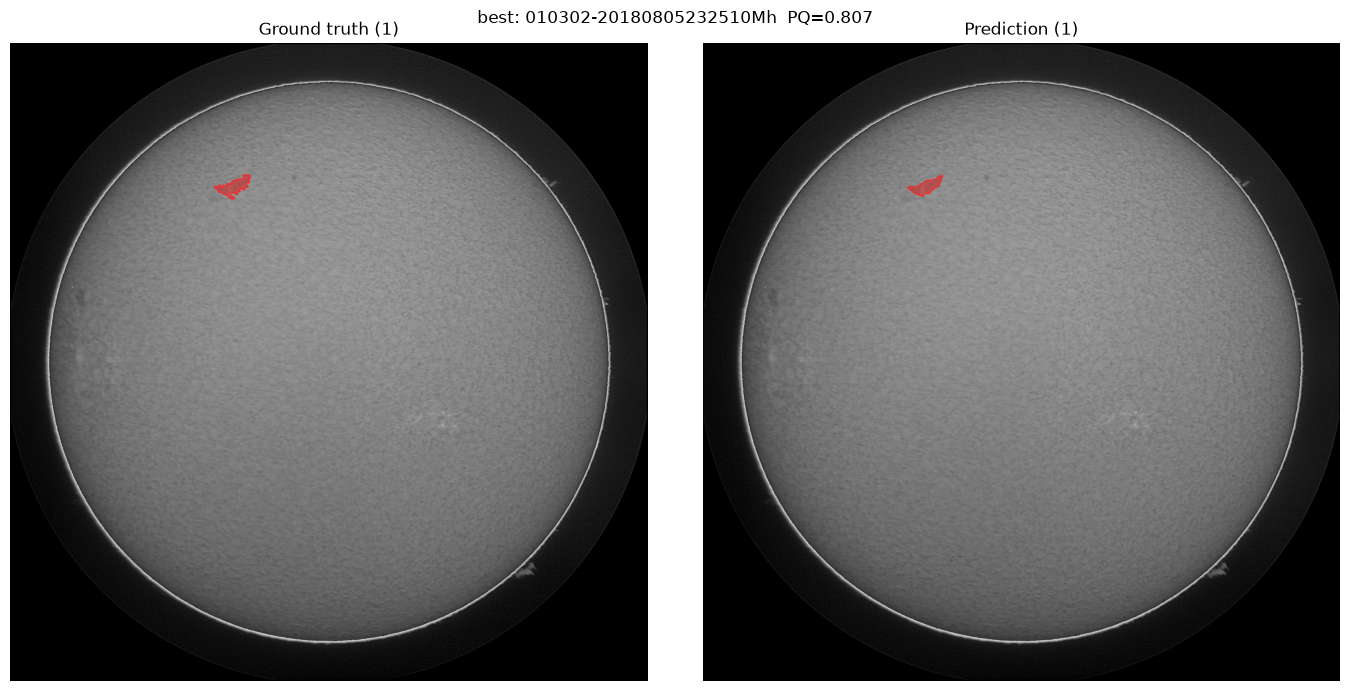

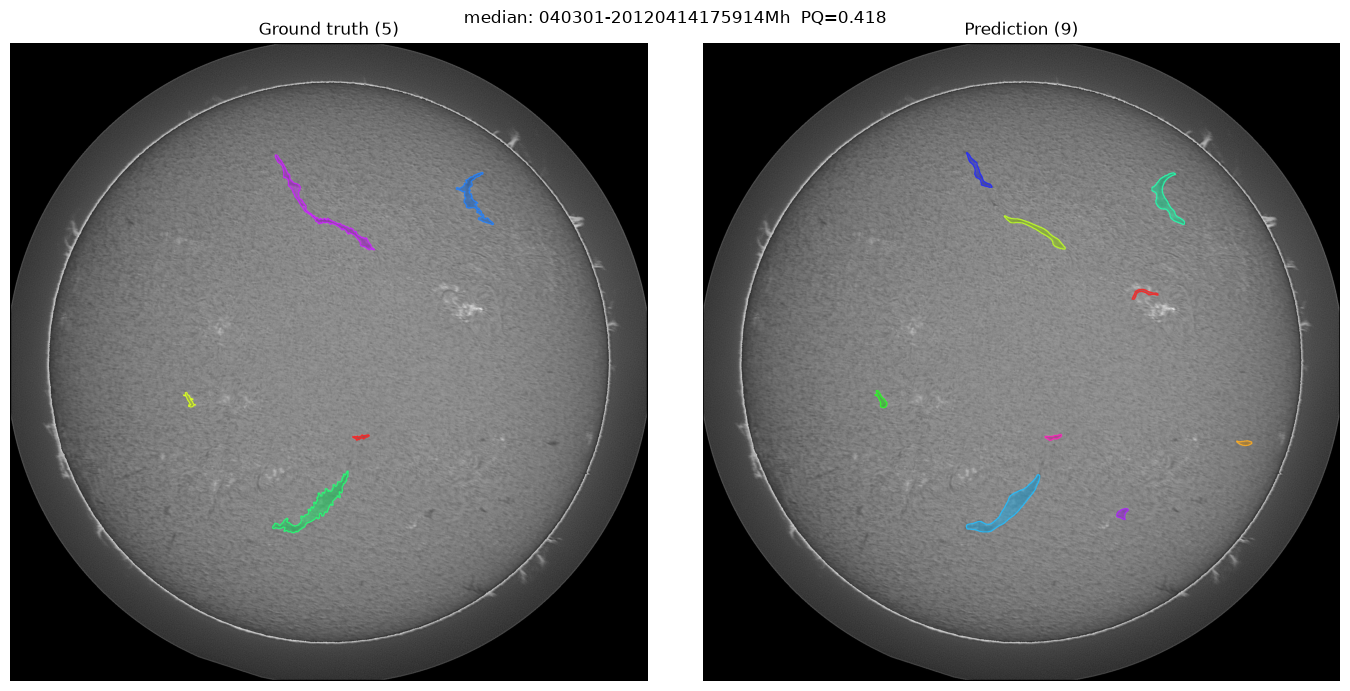

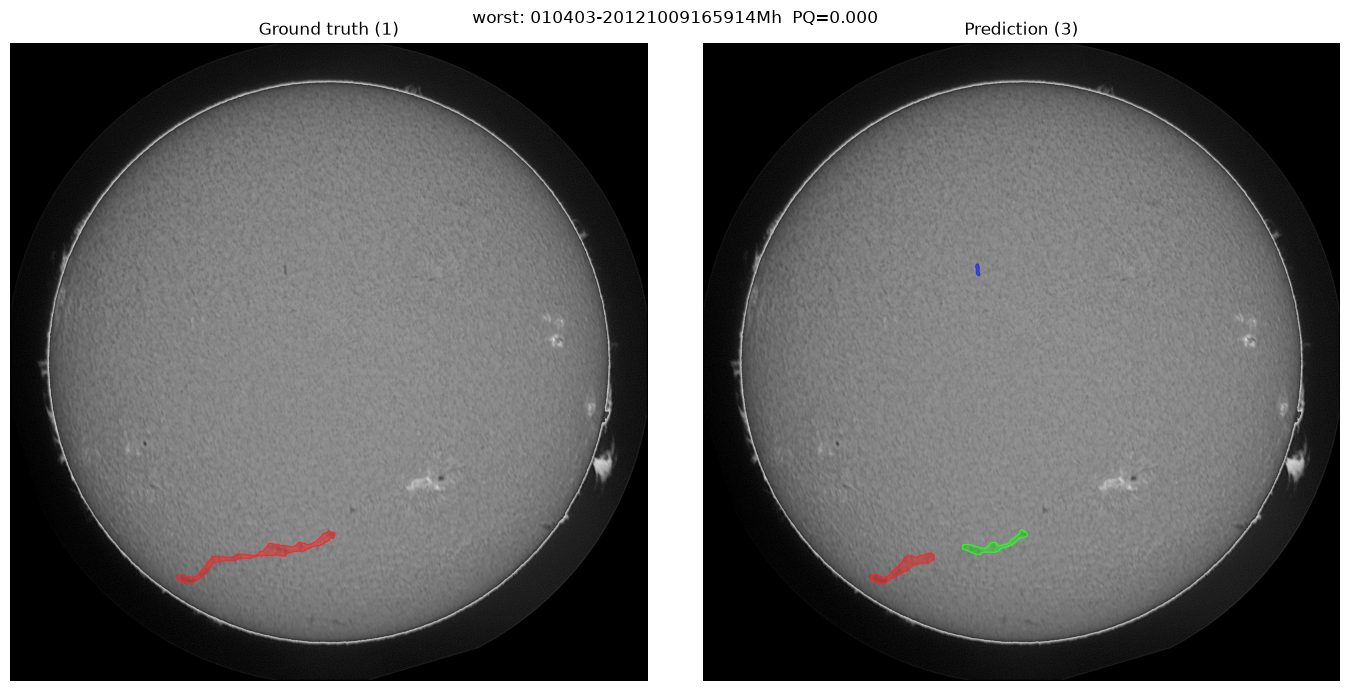

In [10]:
if RUN_VAL:
    order = np.argsort(pq_s)
    img_dir = data_root / cfg["data"]["train_images"]
    for tag, i in [("best", order[-1]), ("median", order[len(order) // 2]), ("worst", order[0])]:
        s = vs.samples[i]
        show_pair(read_gray(img_dir / s["file_name"]), vs.gt[s["sample_id"]], preds[s["timestamp"]],
                  title=f"{tag}: {s['sample_id']}  PQ={pq_s[i]:.3f}"); plt.show()

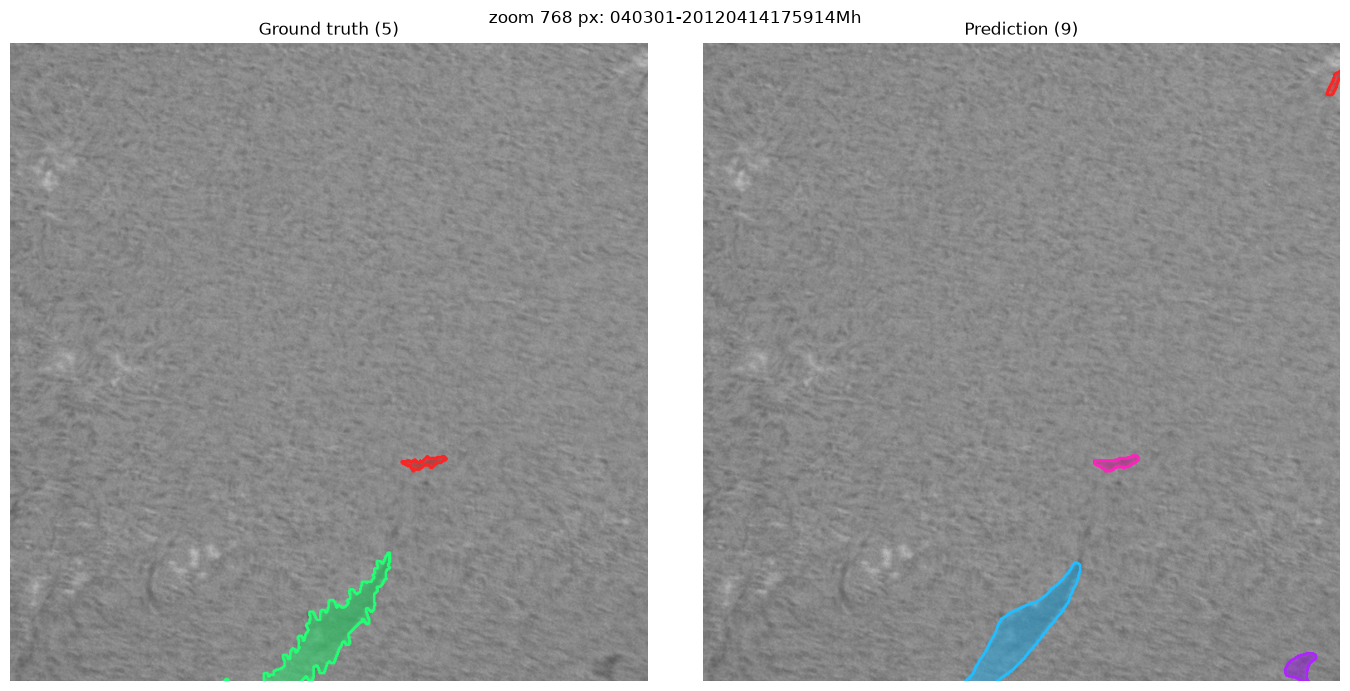

In [11]:
if RUN_VAL:
    s = vs.samples[order[len(order) // 2]]
    gt_union = mask_utils.decode(mask_utils.merge(vs.gt[s["sample_id"]]))
    ys, xs = np.nonzero(gt_union)
    x0 = int(np.clip(np.median(xs) - 384, 0, 2048 - 768)); y0 = int(np.clip(np.median(ys) - 384, 0, 2048 - 768))
    show_pair(read_gray(img_dir / s["file_name"]), vs.gt[s["sample_id"]], preds[s["timestamp"]],
              title=f"zoom 768 px: {s['sample_id']}", crop=(x0, y0, 768)); plt.show()

## 7. Test-set inference and submission

One CSV row per filament: `filament_id` = `<image_id>_<k>`, `segmentation_rle` = COCO RLE counts string
(pycocotools) of the 2048x2048 mask. The CSV is then checked: columns, unique ids, id format, ids belong to
test images, every RLE decodes to 2048x2048 and is non-empty.

In [12]:
test_dir = data_root / cfg["data"]["test_images"]
test_paths = sorted(test_dir.glob("*.jp*g"))
if device.type == "cuda":
    torch.cuda.reset_peak_memory_stats()
t0 = time.time()
test_dets = run_inference(model, test_paths, cfg["model"], device, amp=cfg["train"]["amp"], desc="test")
t_inf = time.time() - t0
t0 = time.time()
sub = write_submission(test_dets, pp, resolve(SUBMISSION))
t_pp = time.time() - t0
assert validate_submission(resolve(SUBMISSION), test_dir)
display(sub.head())

test:   0%|          | 0/180 [00:00<?, ?it/s]

test:   1%|          | 1/180 [00:03<09:01,  3.03s/it]

test:   1%|          | 2/180 [00:05<08:35,  2.90s/it]

test:   2%|▏         | 3/180 [00:08<08:32,  2.90s/it]

test:   2%|▏         | 4/180 [00:11<08:36,  2.93s/it]

test:   3%|▎         | 5/180 [00:14<08:35,  2.95s/it]

... (173 outputs left out)

test:  99%|█████████▉| 179/180 [09:07<00:03,  3.07s/it]

test: 100%|██████████| 180/180 [09:10<00:00,  3.03s/it]

CSV: 1239 rows, 178/180 test images with predictions, 7.0 filaments/img -> OK


,filament_id,segmentation_rle
0,20110120105534Ch_1,k_Ri21no13N2O0hPNKcn17[QNKdn15[QNLen15YQNLfn15...
1,20110120105534Ch_2,dkXn11no11O2L2O1M3O2N2N101O1N100O1000O100O1O1O...
2,20110130110334Ch_1,i_Re24jo15L3N3M3M2O2N3L2O2N1O010O1O001O1O1O1O0...
3,20110214175414Mh_1,X]f[28eo14M3L3L5N1O2N2nNXOjRNi0Tm1ZOiRNg0Wm1ZO...
4,20110214175414Mh_2,hY_g2<ao16L2N1O1O1O0O01000O0010000O100O101O00O...


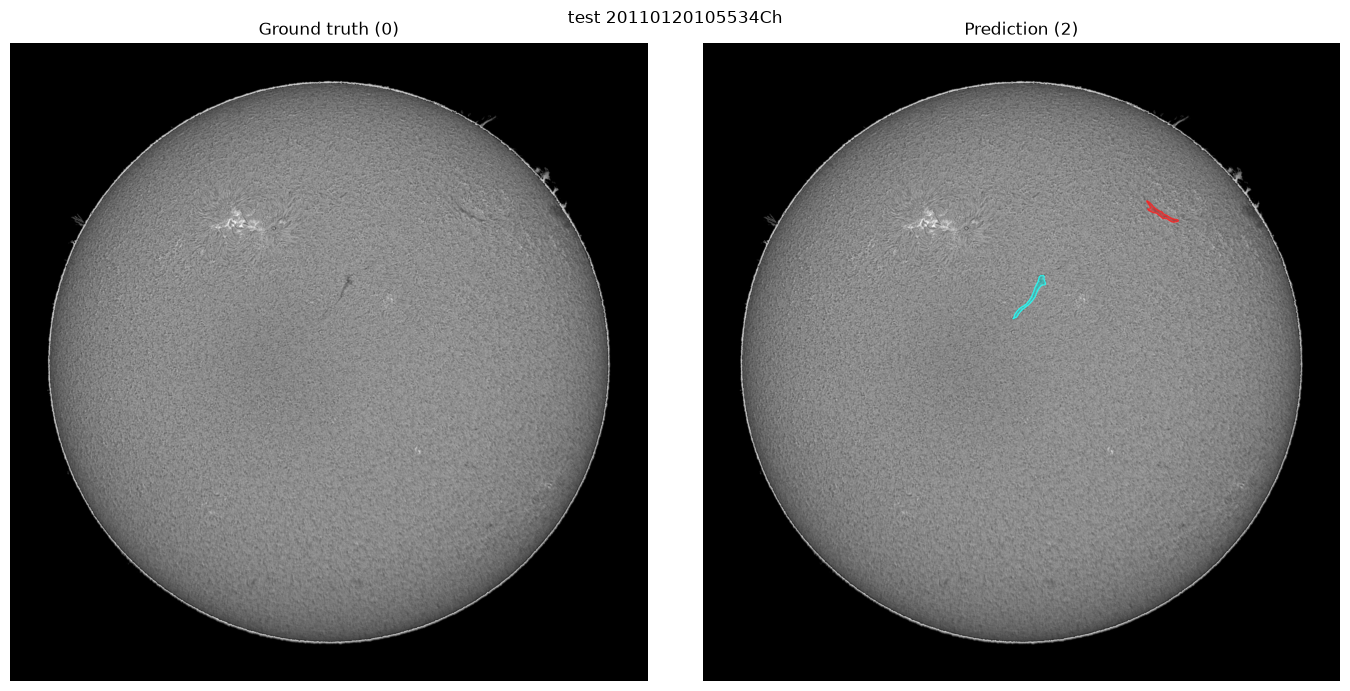

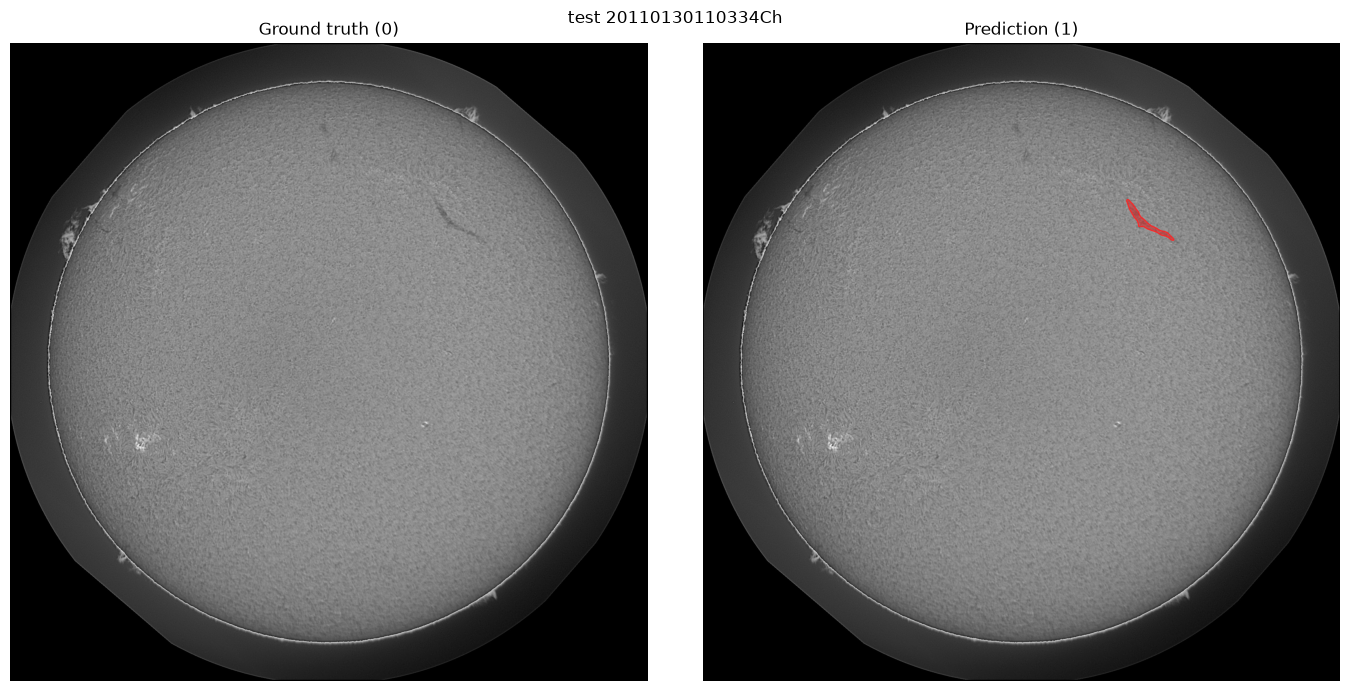

In [13]:
for p in test_paths[:2]:
    rles = instances_to_rles(postprocess(test_dets[p.stem], **{k: pp[k] for k in PP_KEYS}))
    show_pair(read_gray(p), [], rles, title=f"test {p.stem}"); plt.show()

## 8. Computational cost

In [14]:
print("hardware:", torch.cuda.get_device_name(0) if device.type == "cuda" else "CPU")
print(f"test inference: {len(test_paths)} images, {t_inf:.0f}s total, {t_inf / len(test_paths):.2f} s/img (2048x2048, fp32, 3-view flip TTA)")
print(f"post-processing + RLE encoding: {t_pp:.1f}s total")
if device.type == "cuda":
    print(f"peak GPU memory (inference): {torch.cuda.max_memory_allocated() / 2**30:.2f} GB")

hardware: NVIDIA GeForce GTX 1650
test inference: 180 images, 550s total, 3.06 s/img (2048x2048, fp32, 3-view flip TTA)
post-processing + RLE encoding: 5.3s total
peak GPU memory (inference): 2.07 GB
